# Kepler Exoplanet Candidate Vetting with Binary Logistic Regression
**Course:** Statistical Analysis through Programming  
**Dataset:** NASA Kepler Objects of Interest (KOI) cumulative table (`cumulative.csv`, Kaggle)  
**Tools:** `pandas`, `numpy`, `scipy.stats`, `statsmodels`, `scikit-learn`, `matplotlib`

## 1. Problem Statement

A periodic dip in a star's brightness (a *transit*) is not proof of a planet. Eclipsing binaries, grazing stellar eclipses and instrumental variability can all mimic one. Each Kepler Object of Interest (KOI) is eventually labelled `CONFIRMED`, `FALSE POSITIVE` or left as `CANDIDATE`.

> **Can physical and orbital measurements of a transit signal alone separate confirmed planets from false positives, and which measurements carry the most evidence?**

We use binary logistic regression for *inference* (`statsmodels`: odds ratios, confidence intervals) and for *prediction* (`scikit-learn`: precision, recall, F1, ROC-AUC), with a class-weighted model to handle the 2 : 1 class imbalance.

## 2. Data Cleaning & Feature Engineering

We keep `CONFIRMED` (1) and `FALSE POSITIVE` (0), drop `CANDIDATE` rows (no definitive label) and incomplete rows, and fix `SEED = 42`.

**Leakage:** `koi_score` and the `koi_fpflag_*` columns are outputs or defining tests of the vetting process (table below), so they are never used as predictors.

**Predictors:** six physically independent base features. `koi_insol`, `koi_depth` and `koi_srad` were removed because they are near-linear functions of `koi_teq`, `koi_prad` and the other predictors (VIFs above $10^5$ in the earlier version). The five positive, right-skewed features are `log10`-transformed; `koi_steff` stays linear. Two engineered features are added for the models only:

* `log10_koi_prad_sq` lets the model bound the valid radius band instead of assuming monotonic radius effects.
* `period_x_duration` captures transit geometry ($T_{\text{dur}} \propto P^{1/3}$).

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from scipy import stats
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve, confusion_matrix)
from IPython.display import display

SEED = 42
np.random.seed(SEED)

# Consistent colours: planets vs. false positives
C_PLANET, C_FP = "#1b9e77", "#d95f02"

plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25,
    "axes.titlesize": 12, "axes.labelsize": 11, "legend.frameon": False,
})
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

In [2]:
raw = pd.read_csv("cumulative.csv")
labelled = raw[raw["koi_disposition"].isin(["CONFIRMED", "FALSE POSITIVE"])].copy()
labelled["target"] = labelled["koi_disposition"].map({"CONFIRMED": 1, "FALSE POSITIVE": 0})
print(f"Raw table: {len(raw):,} rows -> {len(labelled):,} labelled rows (CANDIDATE dropped)")

# Leakage check: pipeline outputs / vetting flags are never used as predictors
fp_cols = [c for c in raw.columns if c.startswith("koi_fpflag_")]
labelled["any_fpflag"] = labelled[fp_cols].sum(axis=1) > 0
display(labelled.groupby("koi_disposition").agg(
    mean_koi_score=("koi_score", "mean"),
    share_with_any_fpflag=("any_fpflag", "mean")).round(3))

Raw table: 9,564 rows -> 7,316 labelled rows (CANDIDATE dropped)


,mean_koi_score,share_with_any_fpflag
koi_disposition,,
CONFIRMED,0.963,0.024
FALSE POSITIVE,0.015,0.979


In [3]:
# 6 physically independent base predictors (collinear koi_insol, koi_depth, koi_srad removed)
PREDICTORS = ["koi_period", "koi_duration", "koi_prad", "koi_teq", "koi_model_snr", "koi_steff"]
LOG_COLS = ["koi_period", "koi_duration", "koi_prad", "koi_teq", "koi_model_snr"]  # koi_steff stays linear

subset = labelled[PREDICTORS + ["target", "koi_disposition"]].copy()
missing = subset[PREDICTORS].isna().sum()
print("Missing values per predictor:\n" + missing.to_string())
n_before = len(subset)
subset = subset.dropna()
print(f"\nRows after dropna(): {len(subset):,} (removed {n_before - len(subset):,})")

# log10 needs strictly positive values
nonpos = (subset[LOG_COLS] <= 0).any(axis=1)
print(f"Non-positive values in log-transformed columns: {nonpos.sum()}")
subset = subset.loc[~nonpos].copy()

skew_tbl = pd.DataFrame({
    "skew_raw": subset[PREDICTORS].apply(stats.skew),
    "skew_log10": np.log10(subset[PREDICTORS]).apply(stats.skew),
})
skew_tbl["applied"] = np.where(skew_tbl.index.isin(LOG_COLS), "log10", "none (linear)")
display(skew_tbl.round(2))

# Analysis frame: 6 base features (descriptive stats, tests, heatmap) ...
data = subset[["koi_disposition", "target"]].copy()
for c in PREDICTORS:
    data[f"log10_{c}" if c in LOG_COLS else c] = np.log10(subset[c]) if c in LOG_COLS else subset[c]
BASE_FEATURES = [f"log10_{c}" if c in LOG_COLS else c for c in PREDICTORS]

# ... plus two non-linear domain features used only for modelling
data["log10_koi_prad_sq"] = data["log10_koi_prad"] ** 2                          # bounded radius band
data["period_x_duration"] = data["log10_koi_period"] * data["log10_koi_duration"]  # T_dur ~ P^(1/3) geometry
FEATURES = BASE_FEATURES + ["log10_koi_prad_sq", "period_x_duration"]
data = data.reset_index(drop=True)

counts = data["koi_disposition"].value_counts()
print(f"\nFinal sample: {len(data):,} KOIs")
for name, n in counts.items():
    print(f"  {name:<15s} {n:>5,d} ({100 * n / len(data):.1f}%)")

Missing values per predictor:
koi_period         0
koi_duration       0
koi_prad         300
koi_teq          300
koi_model_snr    300
koi_steff        300

Rows after dropna(): 7,016 (removed 300)
Non-positive values in log-transformed columns: 1


,skew_raw,skew_log10,applied
koi_period,2.85,0.43,log10
koi_duration,5.88,0.46,log10
koi_prad,45.66,0.94,log10
koi_teq,3.19,-0.09,log10
koi_model_snr,4.64,0.99,log10
koi_steff,0.90,-0.48,none (linear)



Final sample: 7,015 KOIs
  FALSE POSITIVE  4,723 (67.3%)
  CONFIRMED       2,292 (32.7%)


## 3. Descriptive Statistics & Hypothesis Testing

Summary statistics and two-sample tests use the six base features (analysis scale). Tests are Welch's *t* and Mann-Whitney *U*, with Cohen's *d*, the common-language effect size $P(\text{planet} > \text{FP})$ and a Bonferroni threshold of $\alpha/6$.

In [4]:
def iqr(s):
    return s.quantile(0.75) - s.quantile(0.25)

summary = (data.groupby("koi_disposition")[BASE_FEATURES]
               .agg(["mean", "std", "median", iqr]).T.unstack(level=1))
summary = summary.reindex(
    index=BASE_FEATURES,
    columns=pd.MultiIndex.from_product([["CONFIRMED", "FALSE POSITIVE"], ["mean", "std", "median", "iqr"]]),
)
display(summary.round(3))

CONFIRMED                             FALSE POSITIVE                            
                         mean      std    median      iqr           mean      std    median      iqr
log10_koi_period        1.074    0.537     1.054    0.700          0.955    0.924     0.761    1.440
log10_koi_duration      0.564    0.245     0.553    0.324          0.656    0.363     0.621    0.458
log10_koi_prad          0.354    0.264     0.336    0.284          0.924    0.823     0.836    1.439
log10_koi_teq           2.879    0.201     2.893    0.273          2.990    0.343     3.039    0.494
log10_koi_model_snr     1.584    0.416     1.500    0.431          1.775    0.855     1.467    1.344
koi_steff            5477.974  677.133  5616.000  758.500       5848.830  862.701  5855.000  827.000

In [5]:
planets = data[data["target"] == 1]
fps = data[data["target"] == 0]
n1, n0 = len(planets), len(fps)
alpha_bonf = 0.05 / len(BASE_FEATURES)

rows = []
for f in BASE_FEATURES:
    a, b = planets[f].to_numpy(), fps[f].to_numpy()
    t_stat, p_t = stats.ttest_ind(a, b, equal_var=False)
    u_stat, p_u = stats.mannwhitneyu(a, b, alternative="two-sided")
    pooled_sd = np.sqrt(((n1 - 1) * a.var(ddof=1) + (n0 - 1) * b.var(ddof=1)) / (n1 + n0 - 2))
    rows.append({
        "feature": f,
        "Welch t": t_stat, "Welch p": p_t,
        "Mann-Whitney U": u_stat, "MWU p": p_u,
        "Cohen d": (a.mean() - b.mean()) / pooled_sd,
        "P(planet > FP)": u_stat / (n1 * n0),
        "sig. (Bonferroni)": (p_t < alpha_bonf) and (p_u < alpha_bonf),
    })

tests = pd.DataFrame(rows).set_index("feature")
tests_fmt = tests.copy()
for c in ["Welch p", "MWU p"]:
    tests_fmt[c] = tests_fmt[c].map("{:.2e}".format)
tests_fmt["Welch t"] = tests_fmt["Welch t"].map("{:.2f}".format)
tests_fmt["Mann-Whitney U"] = tests_fmt["Mann-Whitney U"].map("{:,.0f}".format)
tests_fmt["Cohen d"] = tests_fmt["Cohen d"].map("{:+.2f}".format)
tests_fmt["P(planet > FP)"] = tests_fmt["P(planet > FP)"].map("{:.3f}".format)
print(f"n(CONFIRMED) = {n1:,},  n(FALSE POSITIVE) = {n0:,},  Bonferroni alpha = {alpha_bonf:.4f}")
display(tests_fmt)

n(CONFIRMED) = 2,292,  n(FALSE POSITIVE) = 4,723,  Bonferroni alpha = 0.0083


,Welch t,Welch p,Mann-Whitney U,MWU p,Cohen d,P(planet > FP),sig. (Bonferroni)
feature,,,,,,,
log10_koi_period,6.76,1.51e-11,"6,291,162",2.35e-28,+0.14,0.581,True
log10_koi_duration,-12.53,1.35e-35,"4,656,515",2.03e-21,-0.28,0.430,True
log10_koi_prad,-43.24,0.00e+00,"3,647,954",5.26e-109,-0.82,0.337,True
log10_koi_teq,-17.02,1.13e-63,"4,043,650",2.36e-66,-0.37,0.374,True
log10_koi_model_snr,-12.59,5.71e-36,"5,508,062",2.30e-01,-0.26,0.509,False
koi_steff,-19.61,6.97e-83,"3,984,386",4.64e-72,-0.46,0.368,True


Radius shows by far the largest effect (Cohen's *d* ≈ −0.82), followed by `koi_steff` (−0.46) and `koi_teq` (−0.37). Both tests agree everywhere except `log10_koi_model_snr`: the means differ, but ranks do not (P ≈ 0.51, Mann-Whitney *p* = 0.23). False positives have a similar median SNR but a much heavier tail, so SNR is not a good *marginal* separator. These are univariate results; Section 5 adjusts for the other predictors.

## 4. Exploratory Visual Analysis

Large radii and long durations are concentrated among false positives, and confirmed planets cluster in a narrow radius band. The scatter plot below shows the same pattern against the period.

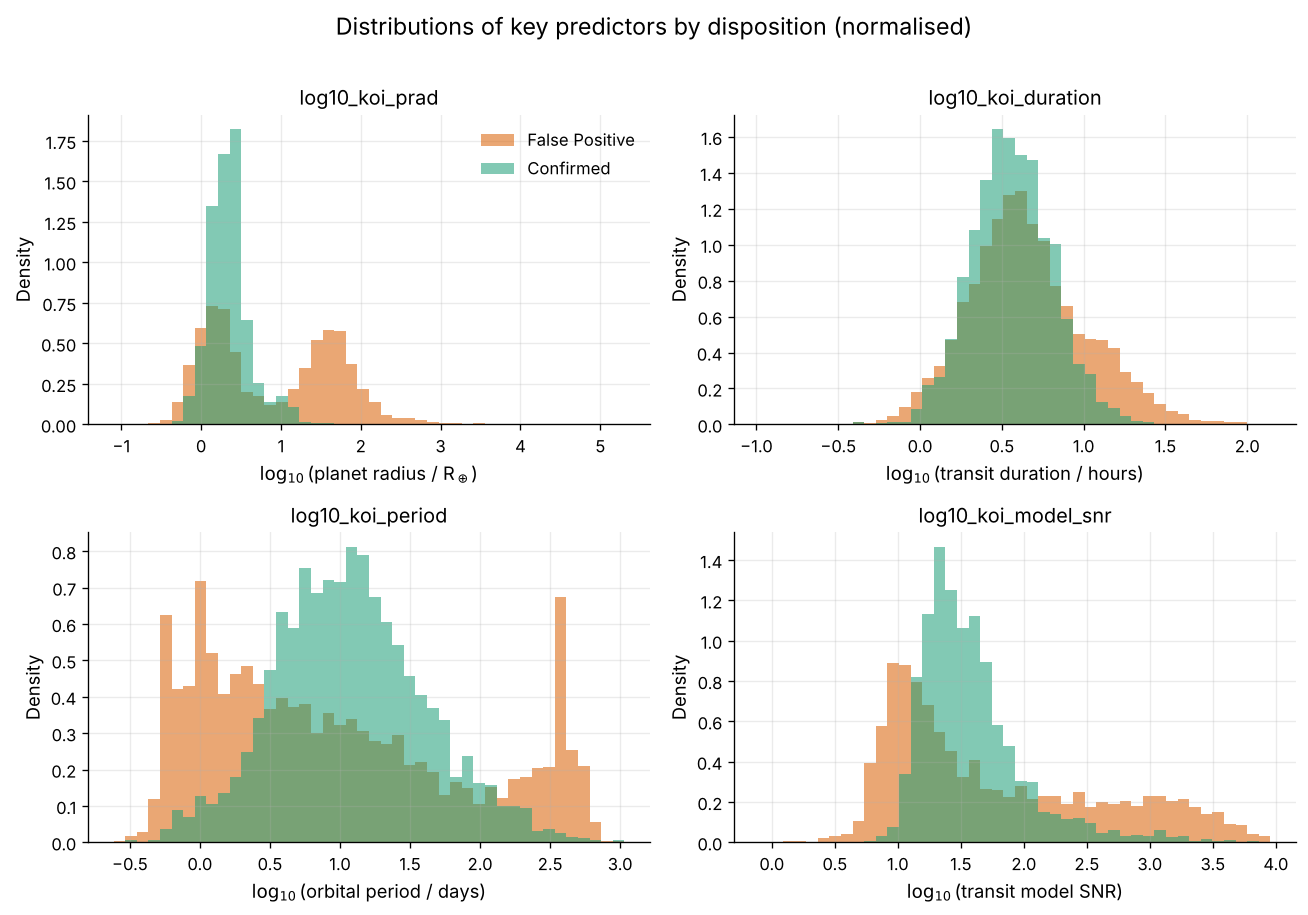

In [6]:
hist_vars = [
    ("log10_koi_prad", r"$\log_{10}$(planet radius / R$_\oplus$)"),
    ("log10_koi_duration", r"$\log_{10}$(transit duration / hours)"),
    ("log10_koi_period", r"$\log_{10}$(orbital period / days)"),
    ("log10_koi_model_snr", r"$\log_{10}$(transit model SNR)"),
]

fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
for ax, (col, xlabel) in zip(axes.ravel(), hist_vars):
    bins = np.linspace(data[col].min(), data[col].max(), 45)
    ax.hist(fps[col], bins=bins, density=True, alpha=0.55, color=C_FP, label="False Positive")
    ax.hist(planets[col], bins=bins, density=True, alpha=0.55, color=C_PLANET, label="Confirmed")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Density")
    ax.set_title(col)
axes[0, 0].legend(loc="upper right")
fig.suptitle("Distributions of key predictors by disposition (normalised)", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

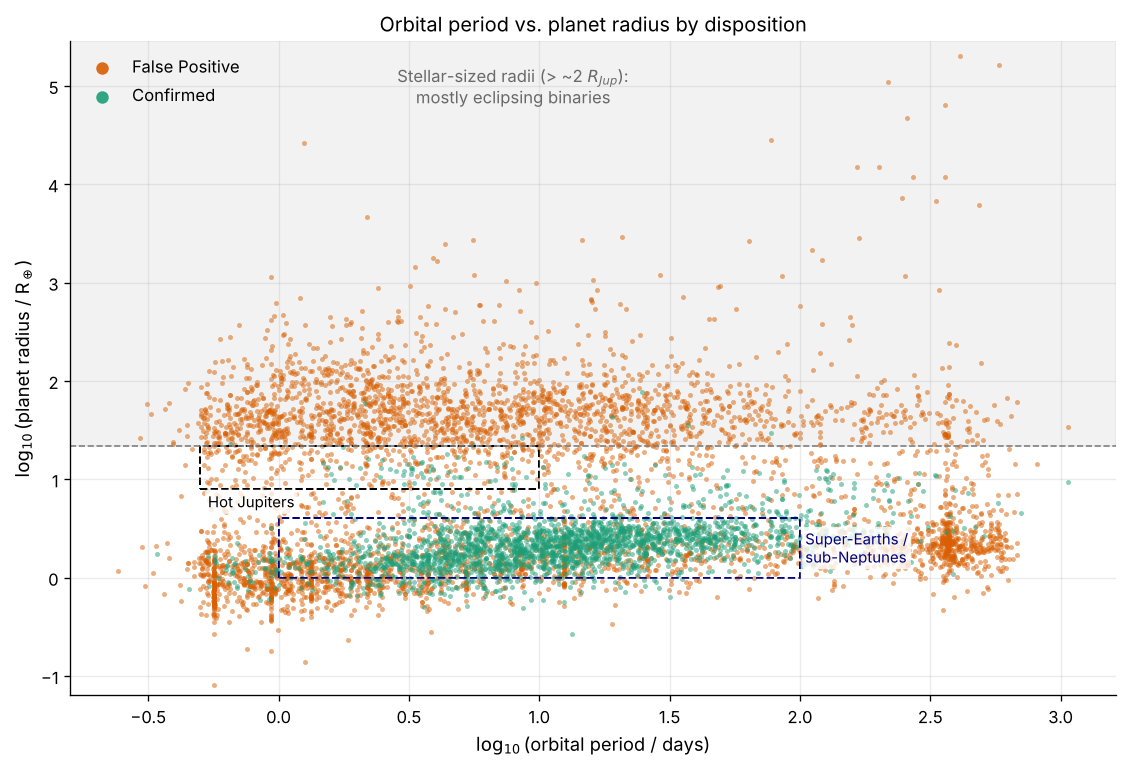

In [7]:
x, y_ = "log10_koi_period", "log10_koi_prad"
fig, ax = plt.subplots(figsize=(9.5, 6.5))
ax.scatter(fps[x], fps[y_], s=9, alpha=0.5, color=C_FP, label="False Positive", linewidths=0)
ax.scatter(planets[x], planets[y_], s=9, alpha=0.5, color=C_PLANET, label="Confirmed", linewidths=0)

R_STELLAR = np.log10(22.0)
y_top = data[y_].max() + 0.15
ax.axhspan(R_STELLAR, y_top, color="gray", alpha=0.10, zorder=0)
ax.axhline(R_STELLAR, color="gray", ls="--", lw=1)
ax.text(0.9, y_top - 0.25, "Stellar-sized radii (> ~2 $R_{Jup}$):\nmostly eclipsing binaries",
        ha="center", va="top", fontsize=10, color="dimgray")

ax.add_patch(Rectangle((np.log10(0.5), np.log10(8)), 1 - np.log10(0.5), R_STELLAR - np.log10(8),
                       fill=False, ec="black", ls="--", lw=1.2))
ax.text(np.log10(0.5) + 0.03, np.log10(8) - 0.04, "Hot Jupiters", fontsize=9, va="top",
        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.8))

ax.add_patch(Rectangle((0, 0), 2, np.log10(4), fill=False, ec="navy", ls="--", lw=1.2))
ax.text(2.02, np.log10(4) / 2, "Super-Earths /\nsub-Neptunes", fontsize=9, va="center", color="navy",
        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.8))

ax.set_xlabel(r"$\log_{10}$(orbital period / days)")
ax.set_ylabel(r"$\log_{10}$(planet radius / R$_\oplus$)")
ax.set_ylim(data[y_].min() - 0.1, y_top)
ax.set_title("Orbital period vs. planet radius by disposition")
leg = ax.legend(loc="upper left", markerscale=2.5)
for h in leg.legend_handles:
    h.set_alpha(0.9)
plt.tight_layout()
plt.show()

The heatmap and VIFs below use the six base features.

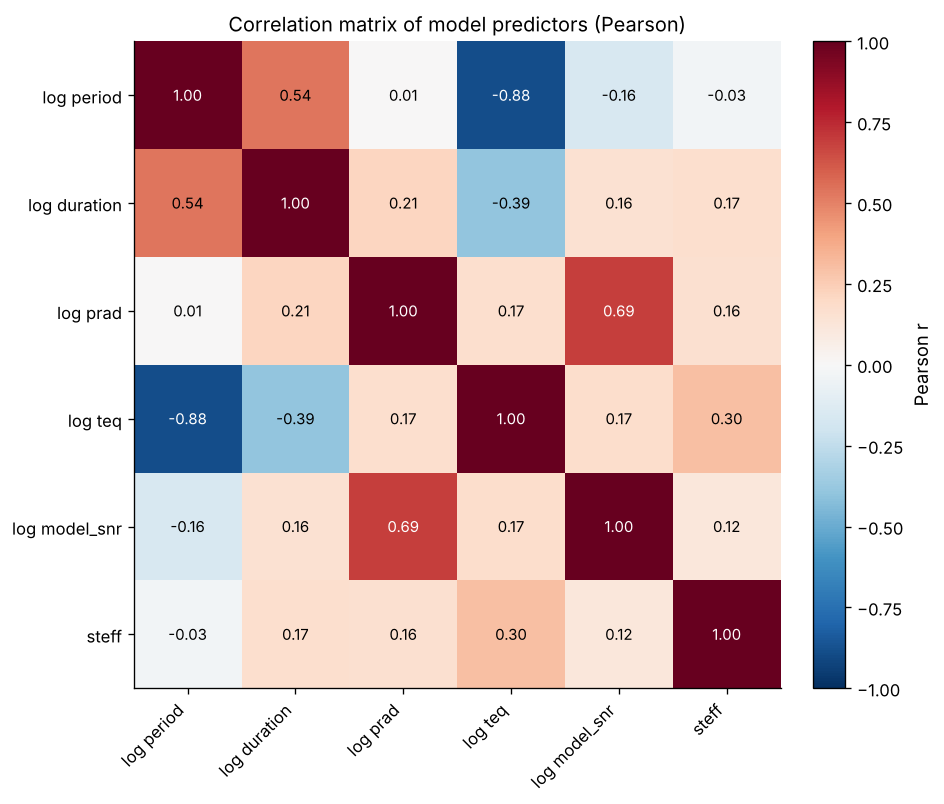

,VIF
log10_koi_period,9.5
log10_koi_duration,1.6
log10_koi_prad,2.6
log10_koi_teq,9.1
log10_koi_model_snr,2.4
koi_steff,1.6


In [8]:
corr = data[BASE_FEATURES].corr()
labels = [f.replace("koi_", "").replace("log10_", "log ") for f in BASE_FEATURES]

fig, ax = plt.subplots(figsize=(8.2, 6.8))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(labels)), labels=labels, rotation=45, ha="right")
ax.set_yticks(range(len(labels)), labels=labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        v = corr.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9,
                color="white" if abs(v) > 0.6 else "black")
ax.grid(False)
ax.set_title("Correlation matrix of model predictors (Pearson)")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Pearson r")
plt.tight_layout()
plt.show()

vif = pd.Series(np.diag(np.linalg.inv(corr.values)), index=BASE_FEATURES, name="VIF")
display(vif.round(1).to_frame())

Collinearity is now mild. The largest VIFs are `log10_koi_period` (9.5) and `log10_koi_teq` (9.1), both below 10 and down from above $10^5$. The pair is linked physically ($T_{eq} \propto a^{-1/2}$ and $a \propto P^{2/3}$), but both stay interpretable. The engineered terms correlate with their parents by construction, so read them jointly with those parents.

## 5. Inferential Logistic Regression (`statsmodels`)

$$\log\frac{P(Y=1\mid \mathbf{x})}{1-P(Y=1\mid \mathbf{x})} = \beta_0 + \sum_{j=1}^{8}\beta_j z_j$$

All 8 modelling features are standardised using the training set only, so each odds ratio is per **+1 SD** with the others held fixed. The split is 80/20 and stratified (`random_state=42`).

In [9]:
X = data[FEATURES]
y = data["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)

scaler = StandardScaler().fit(X_train)           # fit on TRAIN only
X_train_sc = pd.DataFrame(scaler.transform(X_train), columns=FEATURES, index=X_train.index)
X_test_sc = pd.DataFrame(scaler.transform(X_test), columns=FEATURES, index=X_test.index)

print(f"Train: {len(X_train):,} rows  | confirmed share = {y_train.mean():.3f}")
print(f"Test : {len(X_test):,} rows  | confirmed share = {y_test.mean():.3f}")

logit_res = sm.Logit(y_train, sm.add_constant(X_train_sc)).fit(disp=0, maxiter=200)
print(logit_res.summary())

Train: 5,612 rows  | confirmed share = 0.327
Test : 1,403 rows  | confirmed share = 0.326
                           Logit Regression Results                           
Dep. Variable:                 target   No. Observations:                 5612
Model:                          Logit   Df Residuals:                     5603
Method:                           MLE   Df Model:                            8
Date:                Mon, 16 Nov 2026   Pseudo R-squ.:                  0.4796
Time:                        19:19:18   Log-Likelihood:                -1845.3
converged:                       True   LL-Null:                       -3546.2
Covariance Type:            nonrobust   LLR p-value:                     0.000
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                  -4.8596      0.208    -23.347      0.000      -5.268      -4.452
log10_koi_peri

In [10]:
ci = logit_res.conf_int()
ci.columns = ["lo", "hi"]

coef_tbl = pd.DataFrame({
    "Std. coefficient (beta)": logit_res.params,
    "Odds ratio exp(beta)": np.exp(logit_res.params),
    "OR 95% CI lower": np.exp(ci["lo"]),
    "OR 95% CI upper": np.exp(ci["hi"]),
    "p-value": logit_res.pvalues,
}).drop(index="const").sort_values("p-value")

coef_show = coef_tbl.copy()
for c in coef_show.columns[:4]:
    coef_show[c] = coef_show[c].map("{:.3g}".format)
coef_show["p-value"] = coef_show["p-value"].map("{:.2e}".format)
coef_show["significant (p<0.05)"] = np.where(coef_tbl["p-value"] < 0.05, "yes", "no")
display(coef_show)
print(f"McFadden pseudo-R^2 = {logit_res.prsquared:.3f}")

,Std. coefficient (beta),Odds ratio exp(beta),OR 95% CI lower,OR 95% CI upper,p-value,significant (p<0.05)
log10_koi_model_snr,3.54,34.5,25.9,45.9,4.06e-129,yes
log10_koi_prad_sq,-14.2,6.6e-07,1.96e-07,2.23e-06,2.41e-116,yes
log10_koi_period,3.62,37.5,22.7,62,2.30e-45,yes
koi_steff,-1.13,0.323,0.27,0.387,1.63e-34,yes
period_x_duration,-1.47,0.231,0.179,0.297,4.49e-30,yes
log10_koi_teq,2.01,7.48,4.82,11.6,3.30e-19,yes
log10_koi_prad,1.87,6.49,3.8,11.1,8.45e-12,yes
log10_koi_duration,-0.0627,0.939,0.8,1.1,4.44e-01,no


McFadden pseudo-R^2 = 0.480


**Key results** (McFadden pseudo-$R^2$ = 0.48; all odds ratios are per +1 SD):

* **SNR** (OR ≈ 34.5, 95% CI 26–46) is the strongest linear predictor: clean, high-significance transits are rarely false positives.
* **Radius is non-linear.** `log10_koi_prad` is positive (OR ≈ 6.5) while `log10_koi_prad_sq` is strongly negative, so the log-odds peak near $R_p \approx 1.4\,R_\oplus$ and fall for larger radii. This matches the stellar-sized false positives in the scatter plot. The squared term's tiny OR (≈ 7×10⁻⁷ per SD) encodes curvature and should not be read on its own.
* **Period** (OR ≈ 37.5) and **`period_x_duration`** (OR ≈ 0.23) are significant: the model reads duration *relative to the period*, as transit geometry predicts. `log10_koi_duration` alone is no longer significant (*p* = 0.44).
* **`koi_steff`** (OR ≈ 0.32): hotter hosts have lower odds of confirmation. `koi_teq` has OR ≈ 7.5 and is now stable, with a CI of 4.8–11.6, instead of the previous astronomically large values.

`statsmodels` warns about quasi-separation (22% of training rows are perfectly predicted), so the extreme-odds terms should be read directionally. All effects are associations in a catalogue shaped by Kepler's vetting.

## 6. Predictive Evaluation (`scikit-learn`)

We fit an unweighted baseline and a `class_weight="balanced"` model on the same scaled features and compare them on the held-out test set at threshold 0.50. Positive class = `CONFIRMED`.

In [11]:
models = {
    "Baseline (unweighted)": LogisticRegression(max_iter=1000, random_state=SEED),
    "Improved (class_weight='balanced')": LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED),
}
probs, rows = {}, {}
for name, mdl in models.items():
    mdl.fit(X_train_sc, y_train)
    probs[name] = mdl.predict_proba(X_test_sc)[:, 1]
    pred = (probs[name] >= 0.5).astype(int)
    rows[name] = {"Accuracy": accuracy_score(y_test, pred), "Precision": precision_score(y_test, pred),
                  "Recall": recall_score(y_test, pred), "F1-Score": f1_score(y_test, pred),
                  "ROC-AUC": roc_auc_score(y_test, probs[name])}

comparison = pd.DataFrame(rows).T
comparison.loc["Change (improved - baseline)"] = comparison.iloc[1] - comparison.iloc[0]
print("Test-set performance at threshold = 0.50 (positive class = CONFIRMED)")
display(comparison.round(4))
print(f"Always-predict-FALSE-POSITIVE accuracy: {1 - y_test.mean():.4f}")

Test-set performance at threshold = 0.50 (positive class = CONFIRMED)


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Baseline (unweighted),0.8354,0.7473,0.7489,0.7481,0.9185
Improved (class_weight='balanced'),0.8218,0.6667,0.9083,0.7689,0.9176
Change (improved - baseline),-0.0135,-0.0806,0.1594,0.0209,-0.0009


Always-predict-FALSE-POSITIVE accuracy: 0.6736


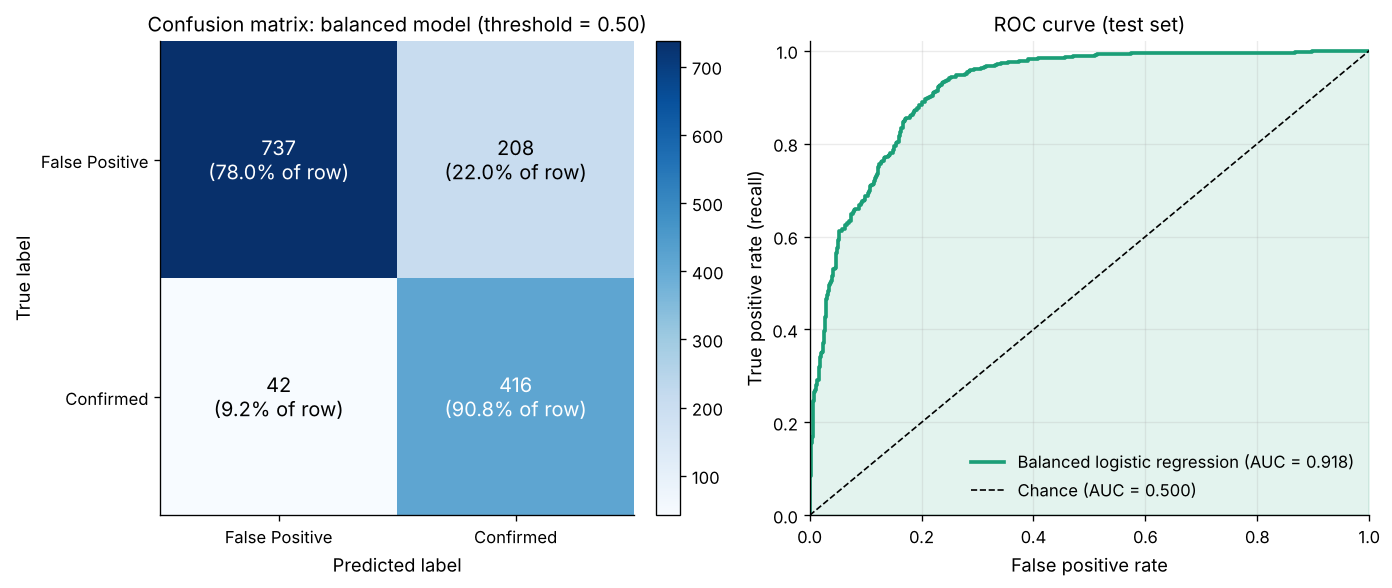

In [12]:
best = "Improved (class_weight='balanced')"
y_prob = probs[best]
y_pred = (y_prob >= 0.5).astype(int)
cm = confusion_matrix(y_test, y_pred)
fpr, tpr, _ = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)
class_names = ["False Positive", "Confirmed"]

fig, (ax_cm, ax_roc) = plt.subplots(1, 2, figsize=(12, 5))
im = ax_cm.imshow(cm, cmap="Blues")
ax_cm.set_xticks([0, 1], labels=class_names)
ax_cm.set_yticks([0, 1], labels=class_names)
ax_cm.set_xlabel("Predicted label")
ax_cm.set_ylabel("True label")
ax_cm.set_title("Confusion matrix: balanced model (threshold = 0.50)")
for i in range(2):
    for j in range(2):
        share = 100 * cm[i, j] / cm[i].sum()
        ax_cm.text(j, i, f"{cm[i, j]:,}\n({share:.1f}% of row)", ha="center", va="center",
                   fontsize=12, color="white" if cm[i, j] > cm.max() / 2 else "black")
ax_cm.grid(False)
fig.colorbar(im, ax=ax_cm, fraction=0.046, pad=0.04)

ax_roc.plot(fpr, tpr, color=C_PLANET, lw=2.2, label=f"Balanced logistic regression (AUC = {auc:.3f})")
ax_roc.plot([0, 1], [0, 1], "k--", lw=1, label="Chance (AUC = 0.500)")
ax_roc.fill_between(fpr, tpr, alpha=0.12, color=C_PLANET)
ax_roc.set_xlabel("False positive rate")
ax_roc.set_ylabel("True positive rate (recall)")
ax_roc.set_title("ROC curve (test set)")
ax_roc.set_xlim(0, 1)
ax_roc.set_ylim(0, 1.02)
ax_roc.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 7. Conclusion & Limitations

**Findings**

* The analysed sample has 7,015 KOIs (32.7% confirmed). Dropping the three collinear predictors brought VIFs to below 10 and made the odds ratios stable.
* The strongest evidence comes from transit SNR, a non-linear radius effect (peak near 1.4 $R_\oplus$), period, host temperature and the period × duration interaction.
* The class-weighted model raises **recall from 0.749 to 0.908** (+0.159) and **F1 from 0.748 to 0.769**, at the cost of precision (0.747 → 0.667) and accuracy (0.835 → 0.822). ROC-AUC is essentially unchanged (0.918 vs. 0.919), so the gain is a shift along the same ranking curve, not a better ranking. Both models beat the 0.674 majority-class accuracy.

**Limitations**

1. **Still a linear model in the log-odds.** Two engineered terms help, but tree ensembles would likely capture more structure.
2. **Recall vs. precision.** The balanced model finds more planets but flags more false positives. If follow-up telescope time is scarce, a higher threshold on the balanced probabilities may be preferable.
3. **Label noise and selection effects.** Labels come from a heterogeneous vetting process that favours bright stars and large planets. `CANDIDATE` rows were excluded.
4. **Single split.** Cross-validation would give uncertainty estimates for the metrics.
5. **Association, not causation.**